# 3P EAL measurement — example analysis (1280 nm)

**Data (`raw_data/`).** One image per depth (8-raster average) from the tissue surface to 860 µm below it (surface z = −5087.3 µm),
excitation attenuated with ND 0.6 + ND 0.3 (≈1/10 power). Each depth was imaged at an EOM setting chosen for that depth.
`raw_data/lookup.csv` converts EOM to excitation power (measured with the ND in place); `raw_data/bg/` is the background frame.

**Analysis.**
1. Subtract the mean of the background frame (scalar) from every image; clip negatives to 0.
2. Gaussian-filter (σ = `GAUSSIAN_SIGMA`) and take the mean of the brightest `TOP_PERCENT` % of pixels → signal *S*.
3. Convert EOM to power *P* with the lookup table.
4. Fit $\ln(S/P^3) = -\frac{3}{\mathrm{EAL}}\,z + c$ over depth $z$; $\mathrm{EAL} = -3/\text{slope}$.

The EAL figure is saved to `../images/eal_fit.png` (and `.svg`).

In [1]:
import re
from pathlib import Path
import xml.etree.ElementTree as ET

import matplotlib as mpl
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.ticker import MultipleLocator
import numpy as np
import pandas as pd
from scipy.ndimage import gaussian_filter

In [2]:
DATA_DIR = Path.cwd() / "raw_data"          # z=<z>_EOM=<eom>-<n> folders, bg/, lookup.csv
IMAGE_DIR = Path.cwd().parent / "images"     # figures used by the protocol README
LOOKUP_TABLE_PATH = DATA_DIR / "lookup.csv"
BACKGROUND_DIR = DATA_DIR / "bg"

LASER_NAME = "1300nm"          # laserPower channel in the XML that the EOM refers to
Z_TOLERANCE_UM = 0.5           # allowed |z(name) - z(XML)|
SURFACE_Z_UM = -5087.3         # depth = z - SURFACE_Z_UM

TOP_PERCENT = 0.1
GAUSSIAN_SIGMA = 5
POWER_LAW_EXPONENT = 3.0
CLIP_NEGATIVE_PIXELS = True

POINT_SIZE = 16                # scatter marker area
POINT_EDGE_WIDTH = 1.0
FIGURE_BASENAME = "eal_fit"

## Helpers

In [3]:
# --- Data loading (PrairieView single-image acquisitions) ---
def parse_folder_name(folder_name):
    """Return (z_um, eom) encoded in a folder name like 'z=-3340.33_EOM9_FOV_108um_avg8-369'."""
    name = Path(folder_name).name
    z_match = re.search(r"z=(-?\d+(?:\.\d+)?)", name)
    eom_match = re.search(r"EOM(?:=)?(\d+)", name)
    z_um = float(z_match.group(1)) if z_match else None
    eom = int(eom_match.group(1)) if eom_match else None
    return z_um, eom


def _find_single_path(folder, pattern, label):
    matches = sorted(Path(folder).glob(pattern))
    if not matches:
        raise FileNotFoundError(f"No {label} found in folder: {folder}")
    if len(matches) > 1:
        raise ValueError(f"Expected exactly one {label} in {folder}, found {len(matches)}")
    return matches[0]


def _pvstate_scalar(root, key, cast=float):
    node = root.find(f".//PVStateShard/PVStateValue[@key='{key}']")
    if node is None or "value" not in node.attrib:
        raise ValueError(f"Missing XML scalar metadata: {key}")
    return cast(node.attrib["value"])


def _pvstate_indexed(root, key, index, cast=float):
    node = root.find(
        f".//PVStateShard/PVStateValue[@key='{key}']/IndexedValue[@index='{index}']"
    )
    if node is None or "value" not in node.attrib:
        raise ValueError(f"Missing XML indexed metadata: {key}[{index}]")
    return cast(node.attrib["value"])


def load_prairie_xml_metadata(xml_path, laser_name=LASER_NAME):
    """Read the global PrairieView state for a single-image acquisition.

    Single-image ('Sequence type="Single"') files store Z and laser power only in the
    top-level PVStateShard, not per frame, so both are read from there.
    """
    xml_path = Path(xml_path)
    root = ET.parse(xml_path).getroot()

    metadata = {
        "bit_depth": int(_pvstate_scalar(root, "bitDepth", int)),
        "pixels_per_line": int(_pvstate_scalar(root, "pixelsPerLine", int)),
        "lines_per_frame": int(_pvstate_scalar(root, "linesPerFrame", int)),
        "rasters_per_frame": int(_pvstate_scalar(root, "rastersPerFrame", int)),
        "microns_per_pixel_x": float(_pvstate_indexed(root, "micronsPerPixel", "XAxis", float)),
        "microns_per_pixel_y": float(_pvstate_indexed(root, "micronsPerPixel", "YAxis", float)),
        "objective_lens_na": float(_pvstate_scalar(root, "objectiveLensNA", float)),
        "optical_zoom": float(_pvstate_scalar(root, "opticalZoom", float)),
    }
    metadata["fov_x_um"] = metadata["pixels_per_line"] * metadata["microns_per_pixel_x"]
    metadata["fov_y_um"] = metadata["lines_per_frame"] * metadata["microns_per_pixel_y"]

    laser_node = root.find(
        f".//PVStateShard/PVStateValue[@key='laserPower']/IndexedValue[@description='{laser_name}']"
    )
    metadata["laser_power_eom"] = (
        float(laser_node.attrib["value"]) if laser_node is not None else None
    )

    z_node = root.find(
        ".//PVStateShard/PVStateValue[@key='positionCurrent']"
        "/SubindexedValues[@index='ZAxis']/SubindexedValue"
    )
    metadata["z_position_um"] = float(z_node.attrib["value"]) if z_node is not None else None
    return metadata


def load_prairie_rawdata(raw_path, n_frames=8, height=512, width=512):
    """Decode one Prairie RAWDATA file and average the repeated frames.

    The uint16 pixel payload starts at byte 0; any extra bytes are trailing padding
    (their size varies between files). This was verified against the 16-bit
    Reference TIFs, which equal the mean of the decoded rasters.
    """
    raw_path = Path(raw_path)
    expected_values = n_frames * height * width
    flat = np.fromfile(raw_path, dtype="<u2")
    if flat.size < expected_values:
        raise ValueError(
            f"RAWDATA file is too small for a {n_frames}x{height}x{width} uint16 payload: {raw_path}"
        )
    frames = flat[:expected_values].reshape(n_frames, height, width)
    return frames.mean(axis=0)


def load_single_acquisition(folder):
    """Load one single-image acquisition folder: averaged image + XML metadata."""
    folder = Path(folder)
    xml_path = _find_single_path(folder, "*.xml", "XML metadata")
    raw_path = _find_single_path(folder, "CYCLE_000001_RAWDATA_*", "RAWDATA file")
    metadata = load_prairie_xml_metadata(xml_path)
    image = load_prairie_rawdata(
        raw_path,
        n_frames=metadata["rasters_per_frame"],
        height=metadata["lines_per_frame"],
        width=metadata["pixels_per_line"],
    )
    return image, metadata


def collect_depth_folders(root_dir):
    """Return acquisition folders that encode both z and EOM in their name."""
    folders = []
    for folder in sorted(Path(root_dir).iterdir()):
        if not folder.is_dir():
            continue
        z_um, eom = parse_folder_name(folder.name)
        if z_um is not None and eom is not None:
            folders.append(folder)
    return folders


def load_power_lookup(lookup_path, eom_column=0, power_column=1):
    """Load the EOM-to-power lookup table (CSV or Excel) from two columns."""
    lookup_path = Path(lookup_path)
    if lookup_path.suffix.lower() == ".csv":
        lookup_df = pd.read_csv(lookup_path, usecols=[eom_column, power_column])
    else:
        lookup_df = pd.read_excel(lookup_path, usecols=[eom_column, power_column])
    lookup_df = lookup_df.dropna(how="any")
    return {int(eom): float(power) for eom, power in zip(lookup_df.iloc[:, 0], lookup_df.iloc[:, 1])}


def subtract_background(image, background_value, clip_negative=True):
    """Subtract a scalar background value from every pixel; optionally clip negatives to zero."""
    corrected = image.astype(float) - float(background_value)
    if clip_negative:
        corrected[corrected < 0] = 0
    return corrected


def top_percent_mean(image, percent):
    """Return the mean of the brightest `percent` pixels in an image."""
    flat_image = image.ravel()
    threshold = np.percentile(flat_image, 100 - percent)
    return np.mean(flat_image[flat_image >= threshold])


def coefficient_of_determination(y_true, y_pred):
    """Return R² for a fitted model."""
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - ss_res / ss_tot


PUB_FONT_FAMILY = ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"]


PUB_FONT_SIZE = 16        # axis titles, legend, in-plot annotation


PUB_TICK_LABEL_SIZE = 14  # numbers along the axes


PUB_ASPECT = (1 + 5 ** 0.5) / 2  # golden ratio plot box, 1.618 (width / height)


PUB_PLOT_BOX_WIDTH_IN = 5.17     # width of the plot box itself, in inches


PUB_PNG_DPI = 200


PUB_TICKS = {
    "major": dict(length=7, width=1.5, direction="in",
                  labelsize=PUB_TICK_LABEL_SIZE),
    "minor": dict(length=3, width=1.5, direction="in"),
}


PUB_MIRROR_TICKS = dict(top=True, right=True)


PUB_LINE_STYLE = dict(color="red", alpha=0.5, linewidth=1.5, linestyle="--",
                      zorder=2)


PUB_POINTS_STYLE = dict(color="#1f77b4", size=40, linewidth=1.8,
                        face_alpha=0.5, zorder=3)


PUB_LEGEND_STYLE = dict(loc="upper right", framealpha=0.8, edgecolor="#cccccc",
                        fancybox=True, borderaxespad=0.8)


def resolve_publication_font():
    """First installed family from PUB_FONT_FAMILY.

    mathtext needs one concrete font name, not a fallback list, so the choice
    has to be made here rather than left to font.sans-serif.
    """
    available = {f.name for f in font_manager.fontManager.ttflist}
    return next(
        (name for name in PUB_FONT_FAMILY if name in available),
        PUB_FONT_FAMILY[-1],
    )


def publication_rc_params():
    """rcParams implementing the lab typography standard.

    Returned as a dict for use inside `matplotlib.rc_context`, so the
    exploratory plots elsewhere in the notebook keep their own defaults.
    """
    font = resolve_publication_font()
    return {
        "font.family": "sans-serif",
        "font.sans-serif": PUB_FONT_FAMILY,
        "font.size": PUB_FONT_SIZE,
        "axes.labelsize": PUB_FONT_SIZE,
        "xtick.labelsize": PUB_TICK_LABEL_SIZE,
        "ytick.labelsize": PUB_TICK_LABEL_SIZE,
        "legend.fontsize": PUB_FONT_SIZE,
        "axes.linewidth": 0.8,
        # Without this, exponents like P^3 fall back to matplotlib's own math
        # font and stop matching the rest of the labels.
        "mathtext.fontset": "custom",
        "mathtext.rm": font,
        "mathtext.it": f"{font}:italic",
        "mathtext.bf": f"{font}:bold",
        "mathtext.cal": font,
        "mathtext.sf": font,
    }


def configure_publication_ticks(ax, x_major, x_minor, y_major, y_minor):
    """Apply the tick-length / direction / spacing standard to one axes."""
    ax.xaxis.set_major_locator(MultipleLocator(x_major))
    ax.xaxis.set_minor_locator(MultipleLocator(x_minor))
    ax.yaxis.set_major_locator(MultipleLocator(y_major))
    ax.yaxis.set_minor_locator(MultipleLocator(y_minor))
    ax.tick_params(which="major", **PUB_MIRROR_TICKS, **PUB_TICKS["major"])
    ax.tick_params(which="minor", **PUB_MIRROR_TICKS, **PUB_TICKS["minor"])


def fit_publication_box_width(fig, ax, target_width, aspect):
    """Grow the figure until the plot box is `target_width` inches wide.

    tight_layout sizes the margins to fit the labels, so the box is always
    smaller than the figure by an amount that depends on font size and label
    length. Solving for it iteratively keeps the plot-box width honest; the
    margins are near-constant in inches, so this converges in a pass or two.
    """
    for _ in range(5):
        fig.tight_layout()
        box = ax.get_window_extent().transformed(fig.dpi_scale_trans.inverted())
        fig_w, fig_h = fig.get_size_inches()
        fig.set_size_inches(target_width + (fig_w - box.width),
                            target_width / aspect + (fig_h - box.height))
    fig.tight_layout()

In [4]:
def eal_fit(depth, y):
    slope, intercept = np.polyfit(depth, y, 1)
    return {"slope": slope, "intercept": intercept, "eal": -POWER_LAW_EXPONENT / slope,
            "r2": coefficient_of_determination(y, slope * depth + intercept), "n": len(depth)}


def eal_figure(series, basename, x_major, x_minor, y_major, y_minor, annotation=None, x_min=None, line=None):
    """series: list of dicts(x, y, color, label, fit=(slope, intercept) or None);
    line: optional (slope, intercept, x0, x1) drawn as the overall fit. Saves PNG + SVG."""
    with mpl.rc_context(publication_rc_params()):
        fig, ax = plt.subplots(figsize=(PUB_PLOT_BOX_WIDTH_IN, PUB_PLOT_BOX_WIDTH_IN / PUB_ASPECT))
        for s in series:
            face = mcolors.to_rgb(s["color"]) + (PUB_POINTS_STYLE["face_alpha"],)
            ax.scatter(s["x"], s["y"], s=POINT_SIZE, facecolors=face, edgecolors=s["color"],
                       linewidths=POINT_EDGE_WIDTH, zorder=3, label=s["label"])
            if s.get("fit") is not None:
                xf = np.linspace(np.min(s["x"]), np.max(s["x"]), 100)
                ax.plot(xf, s["fit"][0] * xf + s["fit"][1], color=s.get("fit_color", s["color"]),
                        linestyle="--", linewidth=1.5, zorder=2)
        if line is not None:
            xf = np.linspace(line[2], line[3], 200)
            ax.plot(xf, line[0] * xf + line[1], label="Linear fit", **PUB_LINE_STYLE)
        if annotation:
            ax.text(0.05, 0.05, annotation, transform=ax.transAxes, va="bottom", zorder=4)
        if x_min is not None:
            ax.set_xlim(left=x_min)
        ax.set_xlabel("Depth (µm)")
        ax.set_ylabel(r"ln($S$/$P^{3}$)")
        ax.set_box_aspect(1 / PUB_ASPECT)
        configure_publication_ticks(ax, x_major, x_minor, y_major, y_minor)
        if any(s.get("label") for s in series):
            ax.legend(**PUB_LEGEND_STYLE, fontsize=11).set_zorder(5)
        fit_publication_box_width(fig, ax, PUB_PLOT_BOX_WIDTH_IN, PUB_ASPECT)
        IMAGE_DIR.mkdir(exist_ok=True)
        for ext, kw in (("svg", {}), ("png", {"dpi": PUB_PNG_DPI})):
            fig.savefig(IMAGE_DIR / f"{basename}.{ext}", bbox_inches="tight", **kw)
        plt.show()

## Load data

In [5]:
power = load_power_lookup(LOOKUP_TABLE_PATH)
bg_image, _ = load_single_acquisition(BACKGROUND_DIR)
bg_mean = float(bg_image.mean())

rows, mismatched = [], []
for folder in collect_depth_folders(DATA_DIR):
    z, eom = parse_folder_name(folder.name)
    if eom not in power:
        raise KeyError(f"EOM {eom} ({folder.name}) is not in {LOOKUP_TABLE_PATH.name}")
    image, meta = load_single_acquisition(folder)
    if not (round(meta["laser_power_eom"]) == eom and abs(meta["z_position_um"] - z) <= Z_TOLERANCE_UM):
        mismatched.append(folder.name)
    corrected = subtract_background(image, bg_mean, CLIP_NEGATIVE_PIXELS)
    rows.append({"folder": folder.name, "z_um": z, "eom": eom, "power_mW": power[eom],
                 "signal": top_percent_mean(gaussian_filter(corrected, GAUSSIAN_SIGMA), TOP_PERCENT)})

df = pd.DataFrame(rows)
df["depth_um"] = df["z_um"] - SURFACE_Z_UM
df["log_S_over_P3"] = np.log(df["signal"] / df["power_mW"] ** POWER_LAW_EXPONENT)
df = df.sort_values("depth_um").reset_index(drop=True)

print(f"{len(df)} images, depth {df.depth_um.min():.0f}–{df.depth_um.max():.0f} µm, "
      f"P {df.power_mW.min():.2f}–{df.power_mW.max():.1f} mW, background mean {bg_mean:.1f}")
print("Folder names match XML metadata." if not mismatched else f"XML mismatch: {mismatched}")

122 images, depth 0–860 µm, P 0.53–58.0 mW, background mean 30.9
Folder names match XML metadata.


## EAL fit

EAL = 175.0 µm, R² = 0.9957, n = 122 depths (TOP_PERCENT = 0.1 %, sigma = 5)


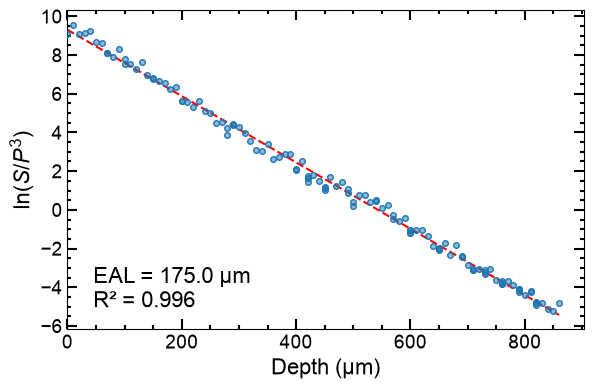

In [6]:
fit = eal_fit(df.depth_um.to_numpy(), df.log_S_over_P3.to_numpy())
print(f"EAL = {fit['eal']:.1f} µm, R² = {fit['r2']:.4f}, n = {fit['n']} depths "
      f"(TOP_PERCENT = {TOP_PERCENT:g} %, sigma = {GAUSSIAN_SIGMA:g})")

eal_figure([dict(x=df.depth_um, y=df.log_S_over_P3, color="#1f77b4", label=None,
                 fit=(fit["slope"], fit["intercept"]), fit_color="red")],
           FIGURE_BASENAME, 200, 50, 2, 0.5,
           annotation=f"EAL = {fit['eal']:.1f} µm\nR² = {fit['r2']:.3f}", x_min=0)